Tech Challenge FASE 4 - Grupo 66

*   Carlos Eduardo Oliveira Possoni
*   Gabriel Ferreira da Silva Pinto
*  Guilherme Borges Faria
* Mariana Barbalho Belo da Silva
* Mateus Resende da Silva



O problema: Imagina que você foi contratado como cientista de dados de um hospital e tem o desafio de desenvolver um modelo de Machine Learning para auxiliar os médicos e médicas a prever se uma pessoa pode ter obesidade.

Requisitos:


1.   Pipeline de machine learning demonstrando toda a etapa de feature
engineering e treinamento do modelo.
2.   Modelo com assertividade acima de 75%.
3. Realizar o deploy do seu modelo em uma aplicação preditiva
utilizando o Streamlit.
4. Construir uma visão analítica em um painel com principais insights
obtidos com o estudo sobre obesidade para trazer insights para a
equipe médica.
5. Compartilhar o link da sua aplicação deployada no app do Streamlit
\+ link do painel analítico + link do repositório do seu github com todo
código desenvolvido em um arquivo .doc ou .txt para realizar o
upload na plataforma online.
6. Gravar um vídeo mostrando toda a estratégia utilizada e apresentação do
sistema preditivo (algo em torno de 4min - 10min). Não se esqueça que
tanto a visão do sistema preditivo quanto o dashboard analítico deve
ser apresentado em uma visão de negócio.






In [1]:
## Importando as bibliotecas necessárias
# Bibliotecas para análise dos dados
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas para criação da pipeline e do modelo
import sklearn
import imblearn
import xgboost
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

# Bibliotecas complementares
import scipy
from scipy import stats
import warnings
import joblib

# Ignorando os avisos para evitar poluição visual
warnings.filterwarnings('ignore')

In [ ]:
# Listando as versões das bibliotecas utilizadas neste notebook
print(f"'pandas'     - Versão: '{pd.__version__}'")
print(f"'numpy'      - Versão: '{np.__version__}'")
print(f"'matplotlib' - Versão: '{matplotlib.__version__}'")
print(f"'seaborn'    - Versão: '{sns.__version__}'")
print(f"'joblib'     - Versão: '{joblib.__version__}'")
print(f"'imblearn'   - Versão: '{imblearn.__version__}'")
print(f"'sklearn'    - Versão: '{sklearn.__version__}'")
print(f"'scipy'      - Versão: '{scipy.__version__}'")
print(f"'xgboost'    - Versão: '{xgboost.__version__}'")

'pandas'     - Versão: '2.2.2'
'numpy'      - Versão: '2.0.2'
'matplotlib' - Versão: '3.10.0'
'seaborn'    - Versão: '0.13.2'
'joblib'     - Versão: '1.5.1'
'imblearn'   - Versão: '0.13.0'
'sklearn'    - Versão: '1.6.1'
'scipy'      - Versão: '1.16.0'
'xgboost'    - Versão: '3.0.2'


In [2]:
# Definindo a aleatoriedade para permitir reprodutibilidade
SEED = 42

In [3]:
# Importando os dados
df = pd.read_csv('Obesity.csv')
df.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [ ]:
# Verificando os valores de cada coluna para traduzir para o português, com o objetivo de construir o dashboard analítico.
for coluna in df.columns:
    print(f'{coluna} - Valor unico:{list(df[coluna].unique())}')

Gender - Valor unico:['Female', 'Male']
Age - Valor unico:[np.float64(21.0), np.float64(23.0), np.float64(27.0), np.float64(22.0), np.float64(29.0), np.float64(24.0), np.float64(26.0), np.float64(41.0), np.float64(30.0), np.float64(52.0), np.float64(20.0), np.float64(19.0), np.float64(31.0), np.float64(39.0), np.float64(17.0), np.float64(25.0), np.float64(55.0), np.float64(38.0), np.float64(18.0), np.float64(15.0), np.float64(61.0), np.float64(44.0), np.float64(34.0), np.float64(36.0), np.float64(32.0), np.float64(35.0), np.float64(40.0), np.float64(45.0), np.float64(33.0), np.float64(51.0), np.float64(56.0), np.float64(28.0), np.float64(16.0), np.float64(37.0), np.float64(14.0), np.float64(25.196214), np.float64(18.503343), np.float64(21.853826), np.float64(21.90012), np.float64(18.306615), np.float64(21.849705), np.float64(19.799054), np.float64(17.188754), np.float64(22.285024), np.float64(21.02497), np.float64(22.038327), np.float64(21.243142), np.float64(22.142432), np.float64(21.

In [4]:
# Criando o dicionário para traduzir as colunas
dicionario_colunas = {
    'Gender': {'Female': 'Feminino', 'Male': 'Masculino'},
    'family_history': {'no': 'Não', 'yes': 'Sim'},
    'FAVC': {'no': 'Não', 'yes': 'Sim'},
    'CAEC': {'no': 'Não', 'Sometimes': 'As vezes', 'Frequently': 'Frequentemente', 'Always': 'Sempre'},
    'SMOKE': {'no': 'Não', 'yes': 'Sim'},
    'SCC': {'no': 'Não', 'yes': 'Sim'},
    'CALC': {'no': 'Não', 'Sometimes': 'As vezes', 'Frequently': 'Frequentemente', 'Always': 'Sempre'},
    'MTRANS': {
        'Public_Transportation': 'Transporte Público', 'Walking': 'Caminhada',
        'Automobile': 'Automóvel', 'Motorbike': 'Motocicleta', 'Bike': 'Bicicleta'
    },
    'Obesity': {
        'Normal_Weight': 'Peso_Normal', 'Overweight_Level_I': 'Sobrepeso_Level_I',
        'Overweight_Level_II': 'Sobrepeso_Level_II', 'Obesity_Type_I': 'Obesidade_Tipo_I',
        'Obesity_Type_II': 'Obesidade_Tipo_II', 'Obesity_Type_III': 'Obesidade_Tipo_III',
        'Insufficient_Weight': 'Abaixo_do_Peso'
    }
}

# Traduzindo o dataframe
for coluna in dicionario_colunas:
    df[coluna] = df[coluna].map(dicionario_colunas[coluna])

df.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Feminino,21.0,1.62,64.0,Sim,Não,2.0,3.0,As vezes,Não,2.0,Não,0.0,1.0,Não,Transporte Público,Peso_Normal
1,Feminino,21.0,1.52,56.0,Sim,Não,3.0,3.0,As vezes,Sim,3.0,Sim,3.0,0.0,As vezes,Transporte Público,Peso_Normal
2,Masculino,23.0,1.80,77.0,Sim,Não,2.0,3.0,As vezes,Não,2.0,Não,2.0,1.0,Frequentemente,Transporte Público,Peso_Normal
3,Masculino,27.0,1.80,87.0,Não,Não,3.0,3.0,As vezes,Não,2.0,Não,2.0,0.0,Frequentemente,Caminhada,Sobrepeso_Level_I
4,Masculino,22.0,1.78,89.8,Não,Não,2.0,1.0,As vezes,Não,2.0,Não,0.0,0.0,As vezes,Transporte Público,Sobrepeso_Level_II


In [5]:
# Verificando valores nulos
df.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


In [ ]:
## Verificando a quantidade de respostas unicas por variável (coluna)
df.nunique()

,0
Gender,2
Age,1402
Height,1574
Weight,1525
family_history,2
FAVC,2
FCVC,810
NCP,635
CAEC,4
SMOKE,2


In [ ]:
# Verificando o tipo das colunas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          2111 non-null   object 
 1   Age             2111 non-null   float64
 2   Height          2111 non-null   float64
 3   Weight          2111 non-null   float64
 4   family_history  2111 non-null   object 
 5   FAVC            2111 non-null   object 
 6   FCVC            2111 non-null   float64
 7   NCP             2111 non-null   float64
 8   CAEC            2111 non-null   object 
 9   SMOKE           2111 non-null   object 
 10  CH2O            2111 non-null   float64
 11  SCC             2111 non-null   object 
 12  FAF             2111 non-null   float64
 13  TUE             2111 non-null   float64
 14  CALC            2111 non-null   object 
 15  MTRANS          2111 non-null   object 
 16  Obesity         2111 non-null   object 
dtypes: float64(8), object(9)
memory u

# Verificando a distribuição das variáveis categóricas

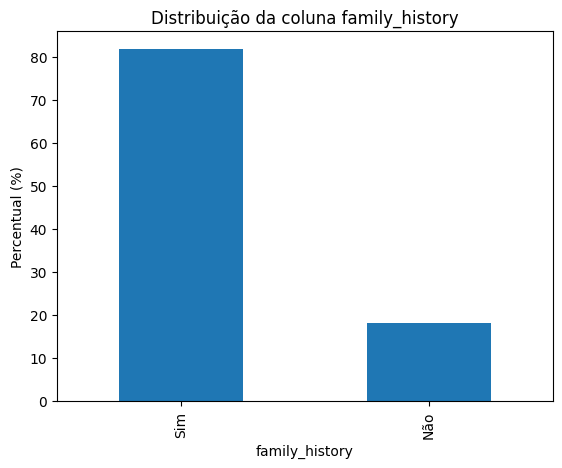

In [ ]:
# Verificando a distribuição da coluna family_history: Algum membro da família sofreu ou sofre de excesso de peso?
(df['family_history'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna family_history')
plt.ylabel('Percentual (%)')
plt.show()

A maioria das pessoas possui histórico familiar

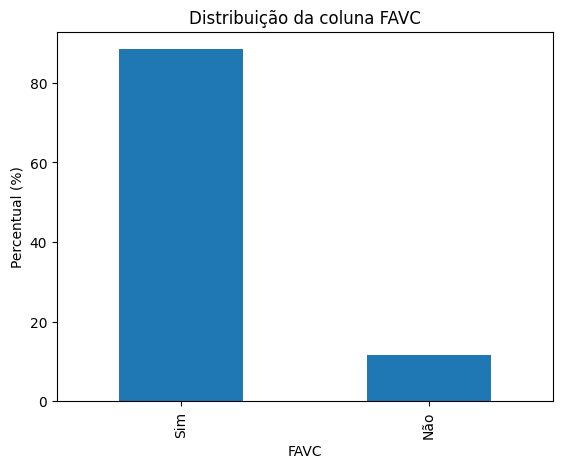

In [ ]:
# Verificando a distribuição da coluna FAVC: Você come alimentos altamente calóricos com frequência?
(df['FAVC'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna FAVC')
plt.ylabel('Percentual (%)')
plt.show()

A maioria das pessoas come alimentos altamente calóricos com frequência

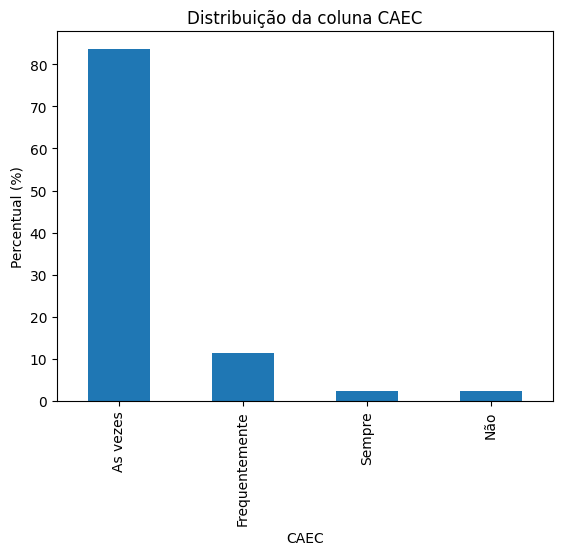

In [ ]:
# Verificando a distribuição da coluna CAEC: Você come alguma coisa entre as refeições?
(df['CAEC'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna CAEC')
plt.ylabel('Percentual (%)')
plt.show()

A maioria das pessoas come alguma coisa entre as refeições as vezes

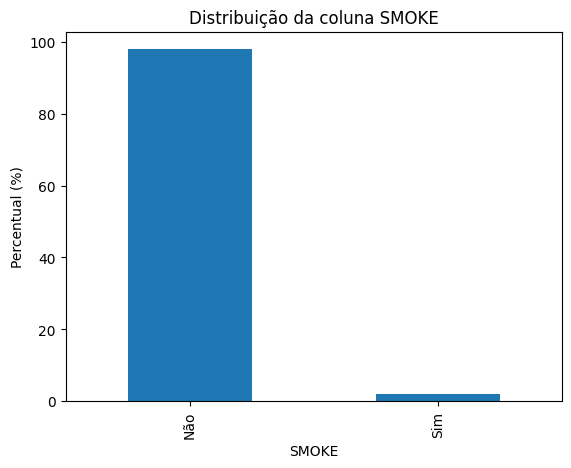

In [ ]:
# Verificando a distribuição da coluna SMOKE: Você fuma?
(df['SMOKE'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna SMOKE')
plt.ylabel('Percentual (%)')
plt.show()

A maioria dos entrevistados não fuma

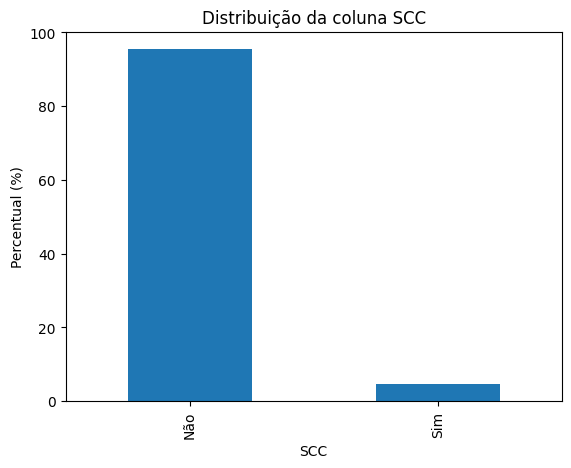

In [ ]:
# Verificando a distribuição da coluna SCC: Você monitora as calorias que ingere diariamente?
(df['SCC'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna SCC')
plt.ylabel('Percentual (%)')
plt.show()

A maioria dos entrevistados não monitora as calorias ingeridas

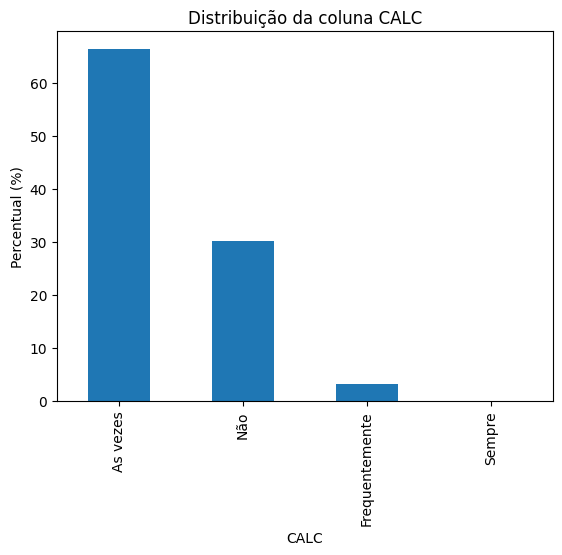

In [ ]:
# Verificando a distribuição da coluna CALC: Com que frequência você bebe álcool?
(df['CALC'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna CALC')
plt.ylabel('Percentual (%)')
plt.show()

A maioria dos entrevistados bebe alcool as vezes

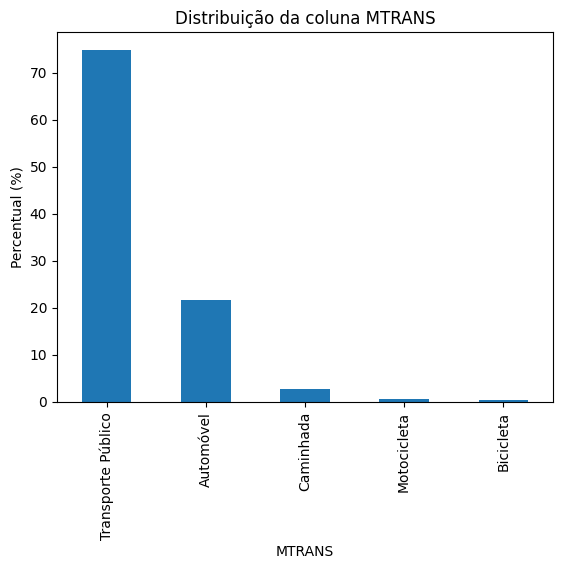

In [ ]:
# Verificando a distribuição da coluna MTRANS: Qual meio de transporte você costuma usar?
(df['MTRANS'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da coluna MTRANS')
plt.ylabel('Percentual (%)')
plt.show()

A maioria dos entrevistado utiliza transporte público

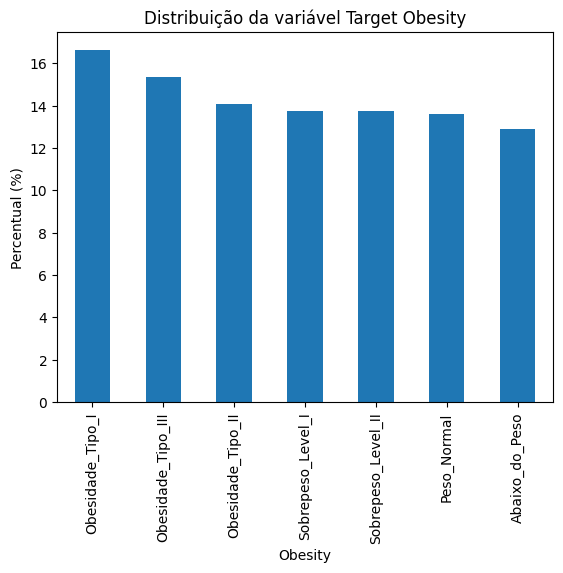

In [ ]:
# Verificando a distribuição da coluna Target (Obesity)
(df['Obesity'].value_counts(normalize=True) * 100).plot(kind='bar')
plt.title('Distribuição da variável Target Obesity')
plt.ylabel('Percentual (%)')
plt.show()

Podemos observar que a proporção das classes está bem distribuida


# Verificando a distribuição das variáveis numéricas

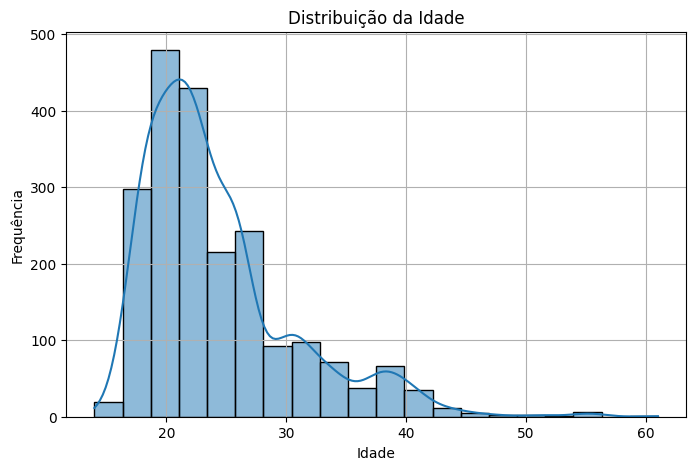

In [ ]:
# Verificando a distribuição das idades
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title("Distribuição da Idade")
plt.xlabel("Idade")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

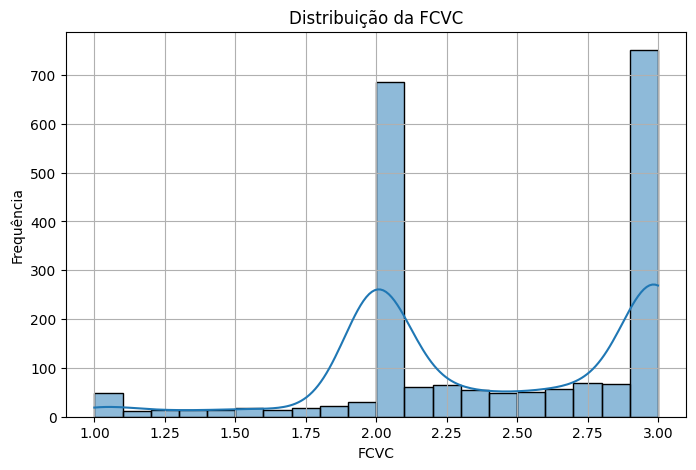

In [ ]:
# Verificando a distribuição do FCVC: Você costuma comer vegetais nas suas refeições?
plt.figure(figsize=(8, 5))
sns.histplot(df['FCVC'], bins=20, kde=True)
plt.title("Distribuição da FCVC")
plt.xlabel("FCVC")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

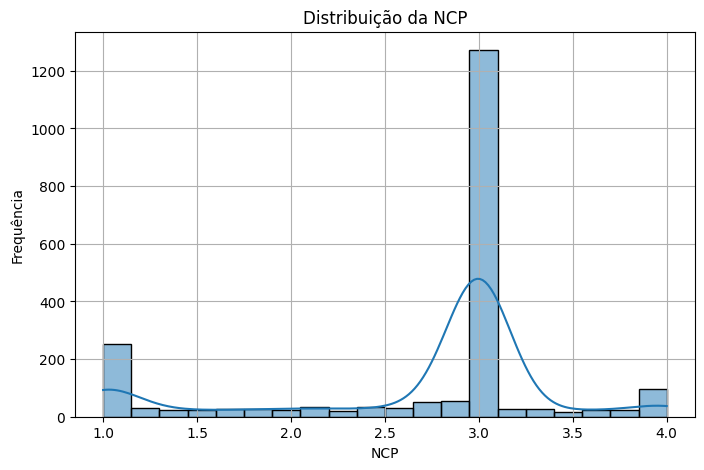

In [ ]:
# Verificando a distribuição do NCP: Quantas refeições principais você faz diariamente?
plt.figure(figsize=(8, 5))
sns.histplot(df['NCP'], bins=20, kde=True)
plt.title("Distribuição da NCP")
plt.xlabel("NCP")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

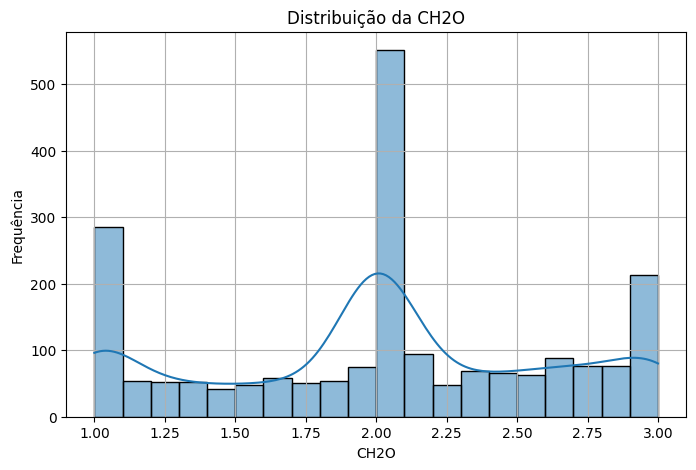

In [ ]:
# Verificando a distribuição de CH2O: Quanta água você bebe diariamente?
plt.figure(figsize=(8, 5))
sns.histplot(df['CH2O'], bins=20, kde=True)
plt.title("Distribuição da CH2O")
plt.xlabel("CH2O")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

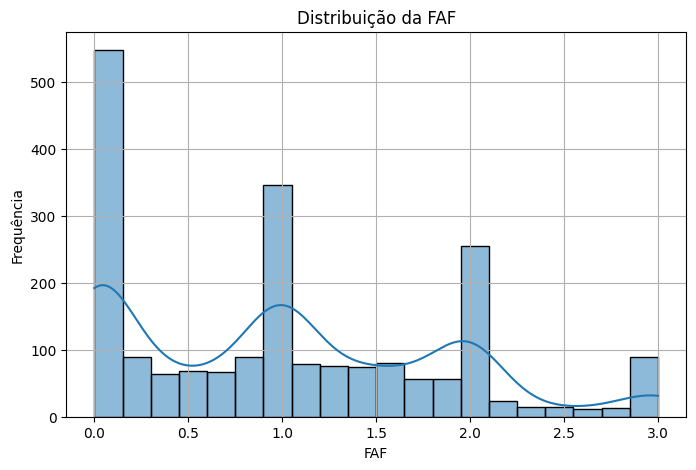

In [ ]:
# Verificando a distribuição das FAF: Com que frequência você pratica atividade física?
plt.figure(figsize=(8, 5))
sns.histplot(df['FAF'], bins=20, kde=True)
plt.title("Distribuição da FAF")
plt.xlabel("FAF")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

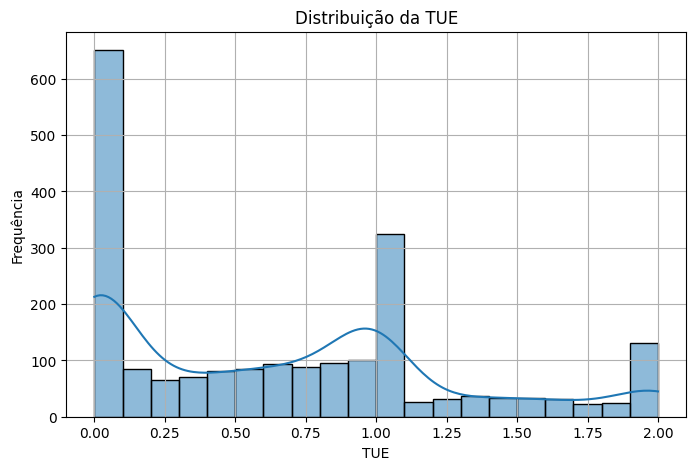

In [ ]:
# Verificando a distribuição de TUE: Quanto tempo você usa dispositivos tecnológicos como celular, videogame, televisão, computador e outros?
plt.figure(figsize=(8, 5))
sns.histplot(df['TUE'], bins=20, kde=True)
plt.title("Distribuição da TUE")
plt.xlabel("TUE")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

Durante a análise exploratória dos dados, observamos a ocorrência de picos em determinados valores inteiros em algumas colunas, o que levantou a hipótese de que esses dados poderiam representar variáveis categóricas. Com base nos padrões identificados nas categorias das outras colunas, optamos por aplicar transformações para variáveis categóricas.

No entanto, ao analisar especificamente a coluna TUE, verificamos que sua distribuição não permitiu uma interpretação clara. Apesar de consultarmos a documentação do dataset, não foi possível compreender com precisão o significado dos valores contidos nessa coluna. Dado que também não foi possível entrar em contato com o cliente para obter esclarecimentos, optamos por remover essa variável do modelo, a fim de evitar ruído e garantir maior robustez na modelagem.

In [6]:
# FCVC: Você costuma comer vegetais nas suas refeições?
dicionario_fcvc = {0: 'Não', 1: 'Às vezes', 2: 'Sempre'}

df['FCVC'] = (df['FCVC'] - 1).round().astype(int).map(dicionario_fcvc)

In [7]:
# NCP: Quantas refeições principais você faz diariamente?
dicionario_ncp = {
    0: '1 Refeição',
    1: '2 Refeições',
    2: '3 Refeições',
    3: '4 ou mais refeições'
}

df['NCP'] = (df['NCP'] - 1).round().astype(int).map(dicionario_ncp)

In [8]:
# CH2O: Quanta água você bebe diariamente?
dicionario_ch2o = {
    0: 'Até 1 Litro',
    1: 'Entre 1 a 2 Litros',
    2: '2 ou mais Litros'
}

df['CH2O'] = (df['CH2O'] - 1).round().astype(int).map(dicionario_ch2o)

In [9]:
# FAF: Com que frequência você pratica atividade física na semana?
dicionario_faf = {
    0: '0 a 1 dia',
    1: '2 a 3 dias',
    2: '4 a 5 dias',
    3: 'Mais de 5 dias'
}
df['FAF'] = df['FAF'].round().astype(int).map(dicionario_faf)

In [10]:
# TUE: Quanto tempo você usa dispositivos tecnológicos como celular, videogame, televisão, computador e outros?
# Para essa variável não conseguimos compreender o padrão ou lógica aplicada. Por este motivo optamos por remover a variável do modelo

df.drop(columns=['TUE'], inplace=True)

In [ ]:
df.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,CALC,MTRANS,Obesity
0,Feminino,21.0,1.62,64.0,Sim,Não,Às vezes,3 Refeições,As vezes,Não,Entre 1 a 2 Litros,Não,0 a 1 dia,Não,Transporte Público,Peso_Normal
1,Feminino,21.0,1.52,56.0,Sim,Não,Sempre,3 Refeições,As vezes,Sim,2 ou mais Litros,Sim,Mais de 5 dias,As vezes,Transporte Público,Peso_Normal
2,Masculino,23.0,1.80,77.0,Sim,Não,Às vezes,3 Refeições,As vezes,Não,Entre 1 a 2 Litros,Não,4 a 5 dias,Frequentemente,Transporte Público,Peso_Normal
3,Masculino,27.0,1.80,87.0,Não,Não,Sempre,3 Refeições,As vezes,Não,Entre 1 a 2 Litros,Não,4 a 5 dias,Frequentemente,Caminhada,Sobrepeso_Level_I
4,Masculino,22.0,1.78,89.8,Não,Não,Às vezes,1 Refeição,As vezes,Não,Entre 1 a 2 Litros,Não,0 a 1 dia,As vezes,Transporte Público,Sobrepeso_Level_II


In [25]:
# Exportando o dataframe traduzido para a construção do dashboard
df.to_csv('Obesidade.csv', index=False, sep=';')

# Criando a Pipeline

In [11]:
# Criando a classe para transformar os valores das variáveis de idade (Age) e altura (Height) na mesma escala
class MinMax(BaseEstimator, TransformerMixin):
    def __init__(self, features_to_scale=['Age', 'Height']):
        self.features_to_scale = features_to_scale

    def fit(self, df, y=None):
        # Armazena apenas as colunas que existem no DataFrame
        self.cols_present = [col for col in self.features_to_scale if col in df.columns]
        self.scaler = MinMaxScaler()
        self.scaler.fit(df[self.cols_present])
        return self

    def transform(self, df):
        df_copy = df.copy()
        if self.cols_present:
            df_copy[self.cols_present] = self.scaler.transform(df_copy[self.cols_present])
        return df_copy

In [12]:
# Criando a classe para aplicar o one-hot-encode na variavel 'Meio de transporte utilizado para ir ao trabalho' (MTRANS)
# já que ela não segue uma ordem natural

class OneHotEncodeNames(BaseEstimator, TransformerMixin):
    def __init__(self, features_to_encode=['MTRANS']):
        self.features_to_encode = features_to_encode
        self.encoder = None
        self.cols_present = []

    def fit(self, df, y=None):
        self.cols_present = [col for col in self.features_to_encode if col in df.columns]
        if self.cols_present:
            self.encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
            self.encoder.fit(df[self.cols_present])
        return self

    def transform(self, df):
        df_copy = df.copy()
        if not self.cols_present:
            return df_copy

        def one_hot_encode(df_subset, cols):
            one_hot = self.encoder
            one_hot_array = one_hot.transform(df_subset[cols])
            feature_names = one_hot.get_feature_names_out(cols)
            df_one_hot = pd.DataFrame(one_hot_array, columns=feature_names, index=df_subset.index)
            return df_one_hot

        def concat_with_rest(df_original, df_one_hot, cols_encoded):
            rest_features = [col for col in df_original.columns if col not in cols_encoded]
            df_concat = pd.concat([df_original[rest_features], df_one_hot], axis=1)
            return df_concat

        df_one_hot = one_hot_encode(df_copy, self.cols_present)
        df_encoded = concat_with_rest(df_copy, df_one_hot, self.cols_present)
        return df_encoded

In [13]:
# Criando a classe para excluir as features que não serão utilizadas no modelo.

class DropFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, features_to_drop=['Weight', 'MTRANS']):
        self.features_to_drop = features_to_drop

    def fit(self, df, y=None):
        return self

    def transform(self, df):
        df = df.copy()
        # Mantém apenas as colunas que estão no DataFrame
        cols_to_drop = [col for col in self.features_to_drop if col in df.columns]
        df = df.drop(columns=cols_to_drop)
        return df


In [14]:
# Criando a classe para ordernar os valores das classes que seguem uma ordem definida
class OrdinalEncodeNames(BaseEstimator, TransformerMixin):
    def __init__(self, features_to_encode=None):
        if features_to_encode is None:
            self.features_to_encode = ['FCVC', 'NCP', 'CAEC', 'CH2O', 'FAF', 'CALC', 'Obesity']
        else:
            self.features_to_encode = features_to_encode

        self.ordinal_encoder = None

        # Classificando as ordens para utilizar a pipeline no modelo de produção
        self.category_orders = {
            'FCVC': ['Não', 'Às vezes', 'Sempre'],
            'NCP': ['1 Refeição', '2 Refeições', '3 Refeições', '4 ou mais refeições'],
            'CAEC': ['Não', 'As vezes', 'Frequentemente', 'Sempre'],
            'CH2O': ['Até 1 Litro', 'Entre 1 a 2 Litros', '2 ou mais Litros'],
            'FAF': ['0 a 1 dia', '2 a 3 dias', '4 a 5 dias', 'Mais de 5 dias'],
            'CALC': ['Não', 'As vezes', 'Frequentemente', 'Sempre'],
            'Obesity': [
                'Abaixo_do_Peso',
                'Peso_Normal',
                'Sobrepeso_Level_I',
                'Sobrepeso_Level_II',
                'Obesidade_Tipo_I',
                'Obesidade_Tipo_II',
                'Obesidade_Tipo_III'
            ]
        }

    def fit(self, df, y=None):
        self.cols_present = [col for col in self.features_to_encode if col in df.columns]
        categories = [self.category_orders[col] for col in self.cols_present]
        self.ordinal_encoder = OrdinalEncoder(
            categories=categories,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        )
        self.ordinal_encoder.fit(df[self.cols_present])
        return self

    def transform(self, df):
        df_copy = df.copy()
        if self.cols_present:
            df_copy[self.cols_present] = self.ordinal_encoder.transform(df_copy[self.cols_present])
        return df_copy

In [15]:
# Criando a classe para transformar as variáveis binárias
class BinarioTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, features_to_encode=['family_history', 'FAVC', 'SMOKE', 'SCC'], feature_exception=['Gender']):
        self.features_to_encode = features_to_encode
        self.feature_exception = feature_exception

    def fit(self, df, y=None):
        return self

    def transform(self, df):
        df = df.copy()

        # Definindo os valores para utilizar na pipeline
        for col in self.features_to_encode:
            if col in df.columns:
                df[col] = df[col].map({'Sim': 1, 'Não': 0})

        for col in self.feature_exception:
            if col in df.columns:
                df[col] = df[col].map({'Masculino': 0, 'Feminino': 1})

        return df

In [16]:
# Criando a classe para realizar o balanceamento
class Oversample(BaseEstimator, TransformerMixin):
    def __init__(self, target_column='Obesity'):
        self.target_column = target_column

    def fit(self, df, y=None):
        return self

    def transform(self, df):
        df = df.copy()

        # Verifica se a coluna de target existe
        if self.target_column not in df.columns:
            print(f"[AVISO] Coluna '{self.target_column}' não encontrada no DataFrame. Nenhum oversampling será aplicado.")
            return df

        oversample = SMOTE(sampling_strategy='minority', random_state=SEED)
        x = df.drop(columns=[self.target_column])
        y = df[self.target_column]

        x_bal, y_bal = oversample.fit_resample(x, y)

        df_bal = pd.concat([pd.DataFrame(x_bal, columns=x.columns),
                            pd.DataFrame(y_bal, columns=[self.target_column])], axis=1)

        return df_bal

In [17]:
# Criando a função para invocar a pipeline
def criar_pipeline():
  pipeline = Pipeline([
      ('min_max_scaler', MinMax()),
      ('one_hot_encoder', OneHotEncodeNames()),
      ('ordinal_encoder', OrdinalEncodeNames()),
      ('binario_transformer', BinarioTransformer()),
      ('feature_dropper', DropFeatures()),
  ])

  return pipeline

In [18]:
# Separando em dados de treino e teste
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED, #<-- Definida no inicio
    stratify=df['Obesity']  # <-- coluna target
)

In [19]:
# Criando a pipeline e transformando o treino
pipeline = criar_pipeline()
df_atualizado = pipeline.fit_transform(train_df)
df_atualizado.head()

,Gender,Age,Height,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,CALC,Obesity,MTRANS_Automóvel,MTRANS_Bicicleta,MTRANS_Caminhada,MTRANS_Motocicleta,MTRANS_Transporte Público
677,1,0.120551,0.420125,0,0,2.0,2.0,1.0,0,1.0,0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
318,1,0.234043,0.197944,0,1,1.0,2.0,1.0,0,0.0,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
918,1,0.170130,0.522966,1,1,1.0,0.0,1.0,0,1.0,0,1.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0
448,1,0.212766,0.274330,1,1,2.0,0.0,1.0,0,0.0,0,0.0,1.0,5.0,0.0,0.0,0.0,0.0,1.0
1271,1,0.085106,0.408117,1,1,2.0,2.0,1.0,0,1.0,0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,1.0


In [20]:
# Monteando o DataFrame para aplicar o oversample
df_train_transf = df_atualizado.copy()

# Invocando a função
oversample = Oversample()

# Balanceando o dataframe de treino
df_bal = oversample.transform(df_train_transf)

# Separando a variável target das features no dataframe de treino
X_train_bal = df_bal.drop(columns=['Obesity'])
y_train_bal = df_bal['Obesity']

# Transformando o dataframe de teste com a pipeline treinada
df_test_transf = pipeline.transform(test_df)

# Separando a variável target das features no dataframe de teste
X_test = df_test_transf.drop(columns=['Obesity'])
y_test = df_test_transf['Obesity']


print(f'Tamanho treino: {X_train_bal.shape}')
print(f'Tamanho teste: {X_test.shape}')

Tamanho treino: (1751, 18)
Tamanho teste: (423, 18)


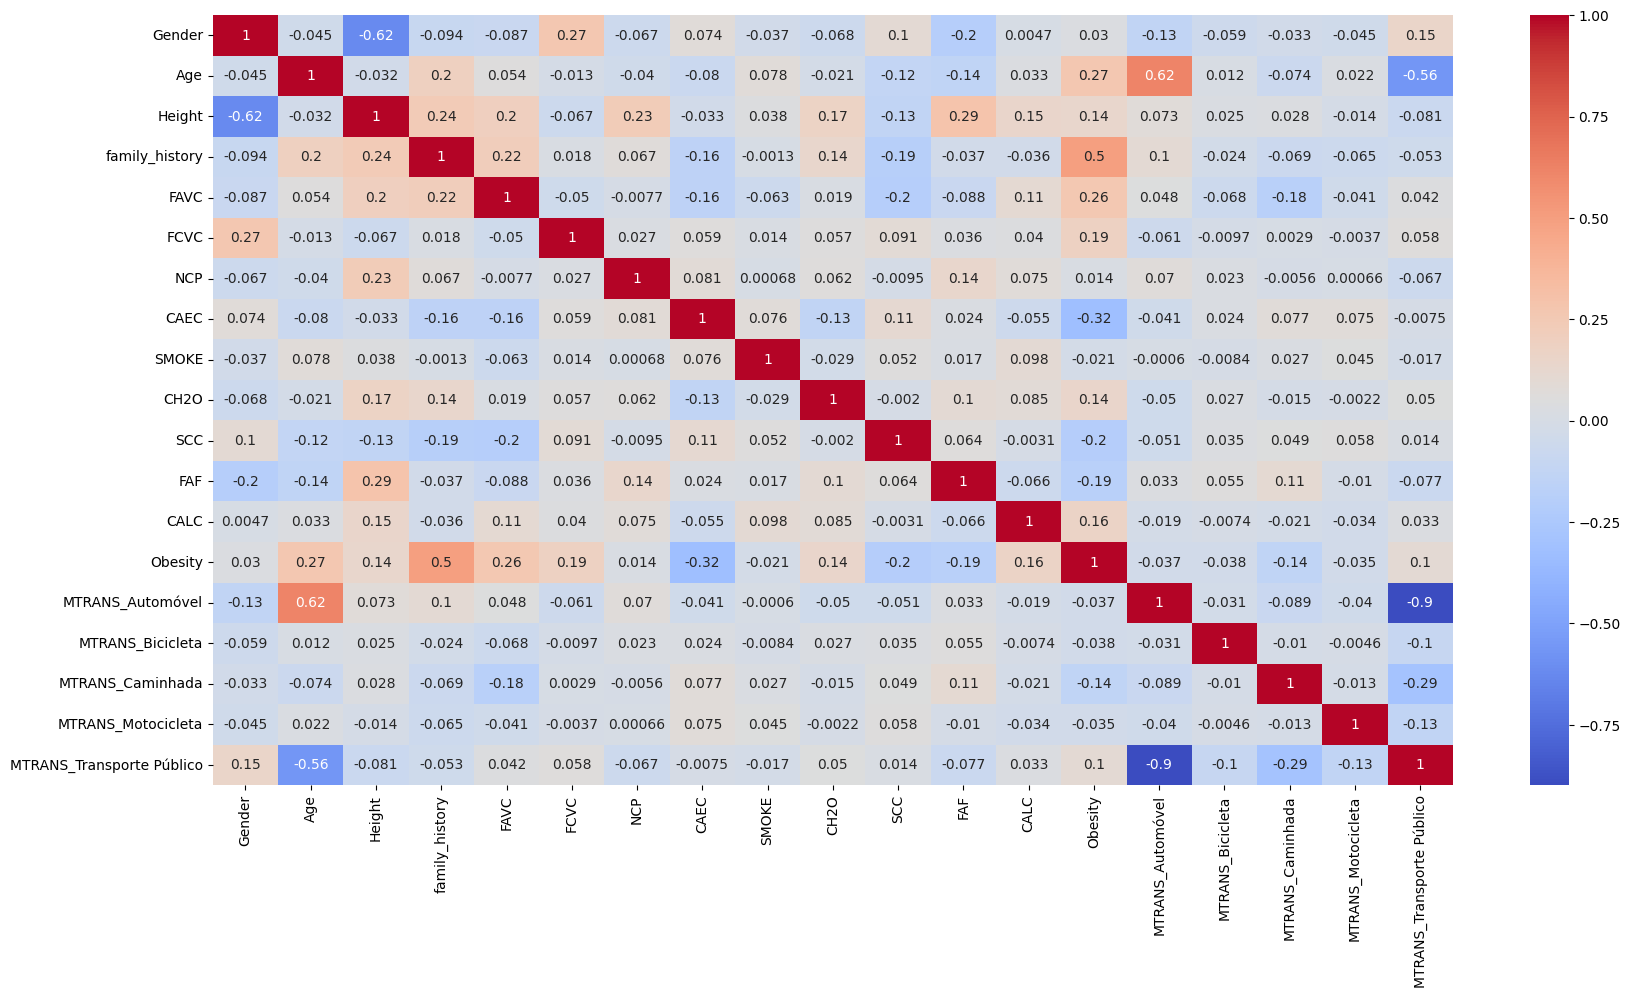

In [ ]:
# Verificando a correlação das variáveis:
correlacao = df_atualizado.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(20, 10))
sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.show()

In [21]:
# Criando uma função para avaliar cada modelo
def roda_modelo(modelo, X_train, y_train, X_test, y_test):
  # Treina o modelo
  modelo.fit(X_train, y_train)

  # Faz a previsão
  y_pred = modelo.predict(X_test)
  prob_pred = modelo.predict_proba(X_test)

  # Imprimi as métricas para avaliar o modelo
  print(f'{classification_report(y_test, y_pred, zero_division=0)}')
  print(f'ROC AUC Score: {roc_auc_score(y_test, prob_pred, multi_class="ovr")}')
  print(f'Acurácia: {metrics.accuracy_score(y_test, y_pred)}')
  print(f'Precisão: {metrics.precision_score(y_test, y_pred, average="weighted")}')
  print(f'Recall: {metrics.recall_score(y_test, y_pred, average="weighted")}')
  print(f'F1 Score: {metrics.f1_score(y_test, y_pred, average="weighted")}')

  # Criando o gráfico com a matriz de confusão para avaliar o modelo
  fig, ax = plt.subplots(figsize=(8, 8))
  matriz_confusao = confusion_matrix(y_test, y_pred,normalize='true')
  sns.heatmap(matriz_confusao, annot=True, cmap='coolwarm', ax=ax)
  ax.set_xlabel('Valores Preditos')
  ax.set_ylabel('Valores Reais')
  ax.set_title('Matriz de Confusão')
  plt.show()

              precision    recall  f1-score   support

         0.0       0.51      0.69      0.59        54
         1.0       0.44      0.21      0.28        58
         2.0       0.49      0.34      0.40        58
         3.0       0.67      0.14      0.23        58
         4.0       0.50      0.73      0.59        70
         5.0       0.57      0.93      0.71        60
         6.0       0.92      1.00      0.96        65

    accuracy                           0.59       423
   macro avg       0.59      0.58      0.54       423
weighted avg       0.59      0.59      0.55       423

ROC AUC Score: 0.8711961233844525
Acurácia: 0.5886524822695035
Precisão: 0.5893141463605417
Recall: 0.5886524822695035
F1 Score: 0.5459996903351791


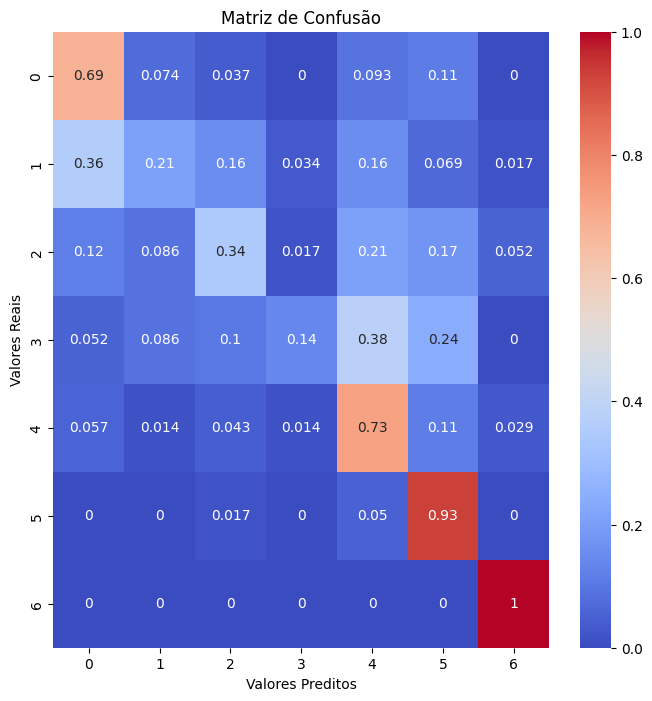

In [ ]:
# Treinando com o modelo Base Line - Regressão Logistica
modelo_regressao = LogisticRegression(random_state=SEED)
roda_modelo(modelo_regressao,X_train_bal, y_train_bal, X_test, y_test)

              precision    recall  f1-score   support

         0.0       0.75      0.81      0.78        54
         1.0       0.58      0.50      0.54        58
         2.0       0.70      0.74      0.72        58
         3.0       0.65      0.64      0.64        58
         4.0       0.70      0.67      0.69        70
         5.0       0.87      0.92      0.89        60
         6.0       0.98      1.00      0.99        65

    accuracy                           0.76       423
   macro avg       0.75      0.75      0.75       423
weighted avg       0.75      0.76      0.75       423

ROC AUC Score: 0.8570312191599003
Acurácia: 0.7565011820330969
Precisão: 0.7516457131380119
Recall: 0.7565011820330969
F1 Score: 0.7532635968553693


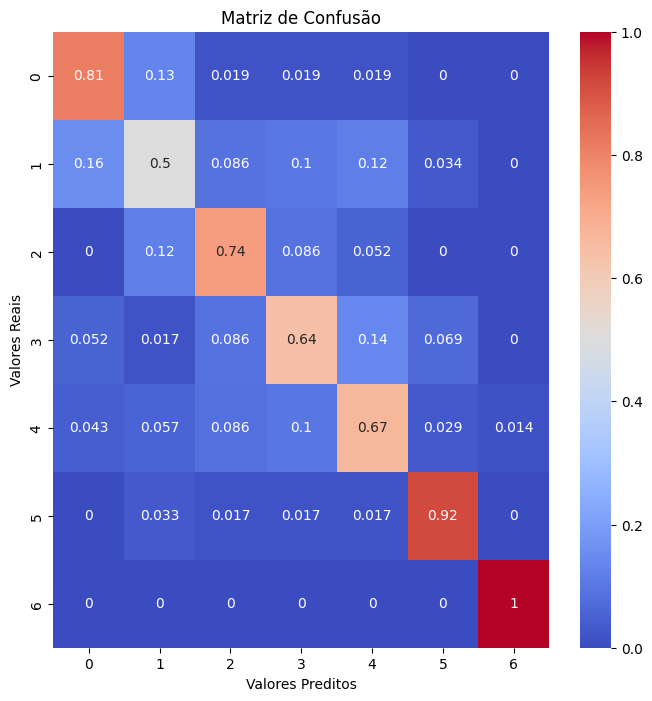

In [ ]:
# Treinando com o modelo - Arvore de Decisão
modelo_decision_tree = DecisionTreeClassifier(random_state=SEED)
roda_modelo(modelo_decision_tree,X_train_bal, y_train_bal, X_test, y_test)

              precision    recall  f1-score   support

         0.0       0.86      0.89      0.87        54
         1.0       0.62      0.67      0.64        58
         2.0       0.79      0.76      0.77        58
         3.0       0.79      0.64      0.70        58
         4.0       0.83      0.81      0.82        70
         5.0       0.91      1.00      0.95        60
         6.0       0.98      1.00      0.99        65

    accuracy                           0.83       423
   macro avg       0.82      0.82      0.82       423
weighted avg       0.83      0.83      0.83       423

ROC AUC Score: 0.9715674816590207
Acurácia: 0.8274231678486997
Precisão: 0.8269696743430678
Recall: 0.8274231678486997
F1 Score: 0.8255805405656904


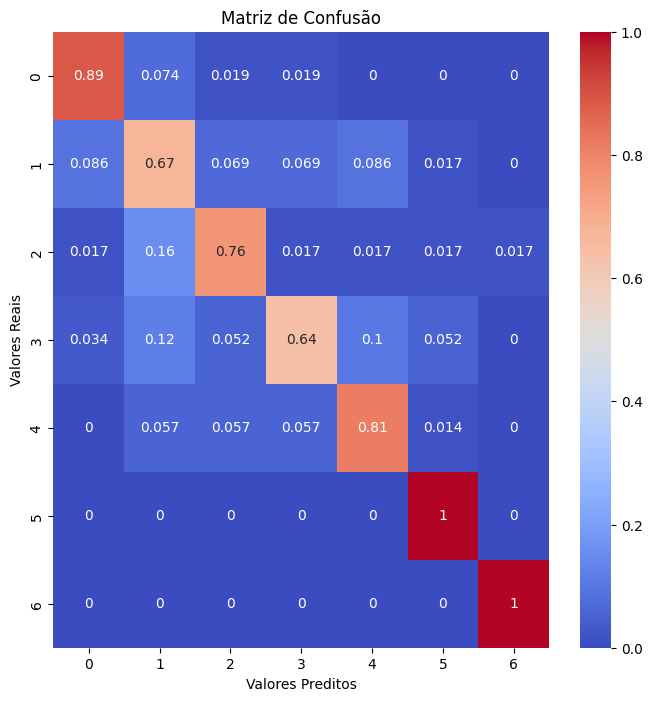

In [ ]:
# Avaliando o modelo RandomForest
modelo_random_forest = RandomForestClassifier(random_state=SEED)
roda_modelo(modelo_random_forest,X_train_bal, y_train_bal, X_test, y_test)

              precision    recall  f1-score   support

         0.0       0.75      0.85      0.80        54
         1.0       0.63      0.67      0.65        58
         2.0       0.87      0.78      0.82        58
         3.0       0.78      0.62      0.69        58
         4.0       0.79      0.80      0.79        70
         5.0       0.88      0.95      0.91        60
         6.0       0.98      1.00      0.99        65

    accuracy                           0.81       423
   macro avg       0.81      0.81      0.81       423
weighted avg       0.81      0.81      0.81       423

ROC AUC Score: 0.9715352903376904
Acurácia: 0.8132387706855791
Precisão: 0.814729546618098
Recall: 0.8132387706855791
F1 Score: 0.8116667737156439


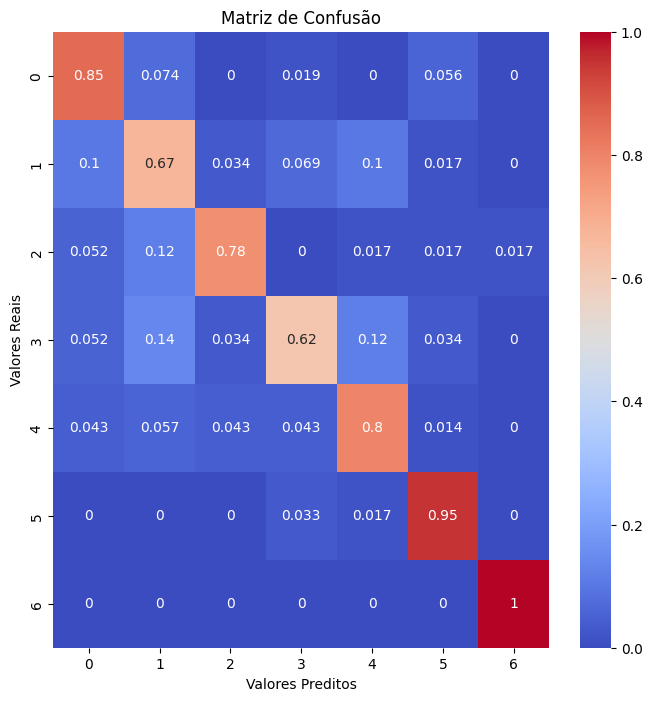

In [ ]:
# Avaliando o modelo XGBOOST
modelo_xgb = XGBClassifier(random_state=SEED)
roda_modelo(modelo_xgb,X_train_bal, y_train_bal, X_test, y_test)

Os modelos XGBoost e RandomForest apresentaram precisão de 81,5% e 82,6%, por este motivo iremos testar ambos os modelos com mais hiperparâmetros para definir o modelo a ser escolhido.

In [ ]:
# Procurando os melhores parâmetros com GridSearch para o modelo Random Forest


param_grid = {
    'n_estimators': [200, 400, 600, 800, 1000],       # mais árvores para estabilidade
    'max_depth': [10, 20, 30, 40, None],              # None permite árvore sem limite
    'min_samples_split': [2, 5, 10],                   # controla splits
    'min_samples_leaf': [1, 2, 4, 6],                  # controla tamanho da folha
    'max_features': ['sqrt', 'log2', None],            # opções clássicas
    'bootstrap': [True, False]                          # testa amostragem com e sem reposição
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=SEED),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_bal, y_train_bal)

print("Melhores parâmetros encontrados:")
print(grid_search.best_params_)

print("Melhor score médio na validação cruzada:")
print(grid_search.best_score_)

melhor_modelo = grid_search.best_estimator_
y_pred = melhor_modelo.predict(X_test)
print("Acurácia no teste:", accuracy_score(y_test, y_pred))


Fitting 5 folds for each of 1800 candidates, totalling 9000 fits
Melhores parâmetros encontrados:
{'bootstrap': False, 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Melhor score médio na validação cruzada:
0.8486593406593407
Acurácia no teste: 0.8321513002364066


              precision    recall  f1-score   support

         0.0       0.84      0.89      0.86        54
         1.0       0.63      0.69      0.66        58
         2.0       0.78      0.74      0.76        58
         3.0       0.83      0.66      0.73        58
         4.0       0.83      0.83      0.83        70
         5.0       0.91      1.00      0.95        60
         6.0       0.98      1.00      0.99        65

    accuracy                           0.83       423
   macro avg       0.83      0.83      0.83       423
weighted avg       0.83      0.83      0.83       423

ROC AUC Score: 0.972308519812227
Acurácia: 0.8321513002364066
Precisão: 0.8324306976837934
Recall: 0.8321513002364066
F1 Score: 0.8303136935755057


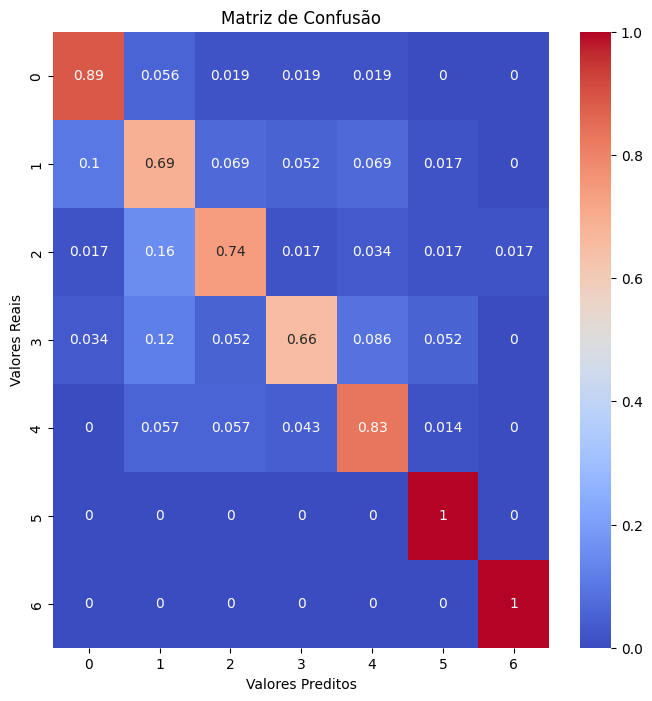

In [22]:
# Avaliando o modelo com a melhor acurácia
modelo_random_forest_best = RandomForestClassifier(
    bootstrap=False,
    max_depth=20,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=2,
    n_estimators=400,
    random_state=SEED
)
roda_modelo(modelo_random_forest_best,X_train_bal, y_train_bal, X_test, y_test)

In [ ]:
# Procurando os melhores parâmetros com GridSearch para o modelo XGBOOST
param_grid_xgb = {
    'n_estimators': [300, 500, 700],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 1],
    'min_child_weight': [1, 5],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [1, 10]
}

xgb_base = XGBClassifier(
    objective='multi:softmax',
    num_class=6,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=SEED,
    n_jobs=-1
)

grid_search_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    scoring='accuracy',
    cv=5,
    verbose=2,
    n_jobs=-1
)

grid_search_xgb.fit(X_train_bal, y_train_bal)

print("\n Melhores parâmetros encontrados:")
print(grid_search_xgb.best_params_)

print("\n Melhor score médio na validação cruzada:")
print(grid_search_xgb.best_score_)

melhor_modelo_xgb = grid_search_xgb.best_estimator_
y_pred_xgb = melhor_modelo_xgb.predict(X_test)

print("\n Acurácia no conjunto de teste:")
print(accuracy_score(y_test, y_pred_xgb))

Fitting 5 folds for each of 1728 candidates, totalling 8640 fits

 Melhores parâmetros encontrados:
{'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.1, 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 500, 'reg_alpha': 0, 'reg_lambda': 1, 'subsample': 1.0}

 Melhor score médio na validação cruzada:
0.8395327635327636

 Acurácia no conjunto de teste:
0.8321513002364066


              precision    recall  f1-score   support

         0.0       0.81      0.85      0.83        54
         1.0       0.65      0.72      0.68        58
         2.0       0.87      0.81      0.84        58
         3.0       0.86      0.64      0.73        58
         4.0       0.80      0.80      0.80        70
         5.0       0.87      0.98      0.92        60
         6.0       0.98      1.00      0.99        65

    accuracy                           0.83       423
   macro avg       0.83      0.83      0.83       423
weighted avg       0.84      0.83      0.83       423

ROC AUC Score: 0.9745104712165598
Acurácia: 0.8321513002364066
Precisão: 0.8357406707223993
Recall: 0.8321513002364066
F1 Score: 0.830629906812607


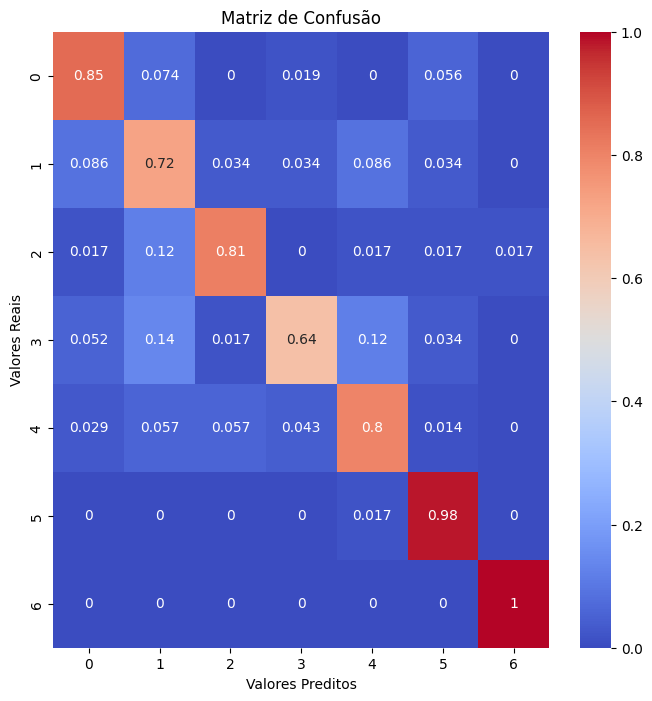

In [ ]:
modelo_xgb_best = XGBClassifier(
    colsample_bytree=0.8,
    gamma=0,
    learning_rate=0.1,
    max_depth=7,
    min_child_weight=1,
    n_estimators=500,
    reg_alpha=0,
    reg_lambda=1,
    subsample=1.0,
    random_state=SEED,
    use_label_encoder=False,
    eval_metric='logloss'
)

roda_modelo(modelo_xgb_best,X_train_bal, y_train_bal, X_test, y_test)

Ambos os modelos apresentaram uma melhora de aproximadamente 2% ao testar diversos hiperparâmetros, sendo o modelo RandomForest o que apresentou a melhor precisão com 83,2% de acurácia, tanto no modelo quanto na validação cruzada.

In [23]:
# Salve pipeline e modelo para utilizar na produção
joblib.dump(pipeline, 'pipeline.pkl')
joblib.dump(modelo_random_forest_best, 'modelo.pkl')

['modelo.pkl']

In [24]:
# Verificando os valores de cada coluna para traduzir para o português, com o objetivo de construir o dashboard analítico.
for coluna in df.columns:
    print(f'{coluna} - Valor unico:{list(df[coluna].unique())}')

Gender - Valor unico:['Feminino', 'Masculino']
Age - Valor unico:[np.float64(21.0), np.float64(23.0), np.float64(27.0), np.float64(22.0), np.float64(29.0), np.float64(24.0), np.float64(26.0), np.float64(41.0), np.float64(30.0), np.float64(52.0), np.float64(20.0), np.float64(19.0), np.float64(31.0), np.float64(39.0), np.float64(17.0), np.float64(25.0), np.float64(55.0), np.float64(38.0), np.float64(18.0), np.float64(15.0), np.float64(61.0), np.float64(44.0), np.float64(34.0), np.float64(36.0), np.float64(32.0), np.float64(35.0), np.float64(40.0), np.float64(45.0), np.float64(33.0), np.float64(51.0), np.float64(56.0), np.float64(28.0), np.float64(16.0), np.float64(37.0), np.float64(14.0), np.float64(25.196214), np.float64(18.503343), np.float64(21.853826), np.float64(21.90012), np.float64(18.306615), np.float64(21.849705), np.float64(19.799054), np.float64(17.188754), np.float64(22.285024), np.float64(21.02497), np.float64(22.038327), np.float64(21.243142), np.float64(22.142432), np.floa